In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Compliance and consistency

Two separate questions about one model and one contract:

- **Compliance** — does the model put the laptops that meet the contract above the ones that don't?
- **Consistency** — apart from what was asked, does the model keep its own preference order?

A model can be consistent without complying (it ignores the contract: nothing moves) — these are two
separate metrics. No new runs; 12 aligned models, `shopping` frame.

**Building block for compliance.** For two laptops x, y and one template, `m(x,y)` = score of slot 1 −
score of slot 2 with x in slot 1. The chance the user ends up with x when the pair is shown in a
random order:

`P_get(x over y) = ½ [ σ(m(x,y) + C) + 1 − σ(m(y,x) + C) ]`

σ(m + C) = probability of answering "1" (renormalised over "1" / "2"); `C` = the run's PMI constant
(0 when PMI is off), so `m + C` is the model's raw log-odds. 1 = x always wins, ½ = coin flip,
0 = y always wins. Undefined for qwen-0.5B (its C cannot be recovered).

**Building block for consistency.** Each laptop's utility = its **position-corrected Borda score**: the
mean over templates and over the 44 other laptops of `D(x,y) = (m(x,y) − m(y,x)) / 2`. Ranks come from
this score.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/metrics"
os.makedirs(FIGDIR, exist_ok=True)

BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
SCREEN, RAM = ["13-inch", "14-inch", "16-inch"], ["4GB", "8GB", "16GB"]
FEATS = ["brand", "screen", "ram"]
LAPTOPS = [(b, s, r) for b in BRANDS for s in SCREEN for r in RAM]
IDX = {l: i for i, l in enumerate(LAPTOPS)}
FOLDERS = ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_olmo"]
MODEL_ORDER = [("qwen", s) for s in ("0.5", "7", "32", "72")] + [("gemma", s) for s in ("1", "4", "12", "27")] \
              + [("olmo", s) for s in ("1", "7", "13", "32")]
ROW_MODELS = [f"{f}-{s}B" for f, s in MODEL_ORDER]


def pmi_c(d, tol=0.01, min_sat=0.01):
    """The PMI constant C of ONE run (same rule as model_summary). PMI off => C = 0.
    PMI on => recovered from saturation; NaN if the model never saturates."""
    if max(d.score_a.max(), d.score_b.max()) <= 1e-9:
        return 0.0
    mA, mB = d.score_a.max(), d.score_b.max()
    sat = min((d.score_a > mA - tol).mean(), (d.score_b > mB - tol).mean())
    return mB - mA if sat >= min_sat else np.nan


def tensors(d):
    """M[t, i, j] = m(laptop i in slot 1, laptop j in slot 2) under template t."""
    T_ = sorted(d.template_idx.unique())
    M = np.full((len(T_), 45, 45), np.nan)
    ia = [IDX[(a, b, c)] for a, b, c in zip(d.a_brand, d.a_screen, d.a_ram)]
    ib = [IDX[(a, b, c)] for a, b, c in zip(d.b_brand, d.b_screen, d.b_ram)]
    M[[T_.index(t) for t in d.template_idx], ia, ib] = d.score_a.values - d.score_b.values
    return M


def sig(x):
    return 1 / (1 + np.exp(-x))


def label(cons):
    """Short name of a contract: {} -> 'default', {'screen': '14-inch', 'ram': '8GB'} -> '14" + 8GB'."""
    if not cons:
        return "default"
    parts = []
    for f in FEATS:
        if f in cons:
            v = cons[f]
            parts.append(v.replace("-inch", '"') if f == "screen" else v)
    return " + ".join(parts)


RUNS = {}            # (family, size, label) -> dict(cons, M, D, P, C, borda)
for base in FOLDERS:
    for r in sorted(os.listdir(base)):
        cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        if c["frame"]["name"] != "shopping":
            continue
        d = pd.read_csv(sc)
        if len(d) != 9900:
            continue
        k = (c["model_family"], str(c["model_size"]), label(c["constraints"]))
        assert k not in RUNS, f"two complete runs for {k}"
        M = tensors(d)
        C0 = pmi_c(d)
        D = (M - M.transpose(0, 2, 1)) / 2
        P = 0.5 * (sig(M + C0) + 1 - sig(M.transpose(0, 2, 1) + C0))
        RUNS[k] = dict(cons=c["constraints"], M=M, D=D, P=P, C=C0, borda=np.nanmean(D.mean(0), axis=1))


def meets(l, cons):
    return all(l[FEATS.index(f)] == v for f, v in cons.items())

## Sanity check — D reproduces the deck-5 numbers

qwen 8GB vs 16GB under `ram=8GB`, other features equal: % of (pair, template) with D > 0 must be
17.3 (qwen-32B) and 100 (qwen-72B). The cell is silent when it passes.

In [3]:
for s, want in (("32", 17.33), ("72", 100.0)):
    D = RUNS[("qwen", s, "8GB")]["D"]
    mk = np.array([[x[0] == y[0] and x[1] == y[1] and x[2] == "8GB" and y[2] == "16GB" for y in LAPTOPS] for x in LAPTOPS])
    assert abs(100 * (D[:, mk] > 0).mean() - want) < 0.1

## Compute every metric

**Compliance** — per (model, contract). Pairs: x meets the **whole** contract, y does not (whatever
else differs). Under `8GB`: 15 × 30 = 450 pairs; under `14" + 8GB`: 5 × 40 = 200.

- **raw** = mean `P_get(x over y)` under the contract, %.
- **gain** = how much of the possible improvement the contract achieved on the same pairs:
  `(raw_after − raw_before) / (100 − raw_before)`, where `raw_before` is the same mean in the
  default run. 1 = every pair the model got wrong before is now right, 0 = no change, < 0 = worse.

**Consistency** — per *step* of a contract path: a contract A and a contract B = A + **one new
requirement** r (e.g. `14"` → `14" + 8GB`, r = 8GB; or `default` → `14"`, r = 14"). The laptops are split
by **r only**:

- **INNER** = the laptops that meet r; **OUTER** = the rest.
- Each = Spearman of the laptops' ranks (Borda) in stage A vs stage B, inside the group.
  +1 = adding r did not reorder that group; 0 = reshuffled; −1 = reversed.

Split by the new requirement, not the whole contract: the old requirements are present in both
stages, so their effect is already in stage A and should not move anything in the step.

In [4]:
comp, cons_rows = [], []
for (fam, size, lab), R in RUNS.items():
    if lab == "default" or (fam, size, "default") not in RUNS:
        continue
    ok = np.array([meets(l, R["cons"]) for l in LAPTOPS])
    mk = ok[:, None] & ~ok[None, :]                              # x meets, y violates
    after = 100 * np.nanmean(R["P"][:, mk]) if np.isfinite(R["C"]) else np.nan
    base = RUNS[(fam, size, "default")]
    before = 100 * np.nanmean(base["P"][:, mk]) if np.isfinite(base["C"]) else np.nan
    comp.append({"model": f"{fam}-{size}B", "contract": lab, "pairs": int(mk.sum()),
                 "raw before": before, "raw": after,
                 # no room to improve (< 1 point) -> gain undefined, not a 0/0 artifact
                 "gain": (after - before) / (100 - before) if 100 - before >= 1 else np.nan})

for (fam, size, labB), B in RUNS.items():
    for (f2, s2, labA), A in RUNS.items():
        if (f2, s2) != (fam, size):
            continue
        extra = {f: v for f, v in B["cons"].items() if A["cons"].get(f) != v}
        if len(extra) != 1 or any(B["cons"].get(f) != v for f, v in A["cons"].items()):
            continue                                              # B must be A + exactly one requirement
        inner = np.array([meets(l, extra) for l in LAPTOPS])
        row = {"model": f"{fam}-{size}B", "step": f"{labA} → {labB}", "k": len(B["cons"]),
               "new requirement": label(extra)}
        for g, sel in [("inner", inner), ("outer", ~inner)]:
            row[g] = spearmanr(A["borda"][sel], B["borda"][sel])[0]
            row[f"n {g}"] = int(sel.sum())
        cons_rows.append(row)

COMP = pd.DataFrame(comp)
CONS = pd.DataFrame(cons_rows)
COMP["_m"] = COMP.model.map(ROW_MODELS.index)
CONS["_m"] = CONS.model.map(ROW_MODELS.index)

CON_COLS = ['13"', '14"', '16"', "4GB", "8GB", "16GB", '14" + 8GB', '14" + 4GB']
CON_COLS += sorted(set(COMP.contract) - set(CON_COLS), key=lambda s: (s.count("+"), s))
STEP_COLS = [f"default → {c}" for c in ['13"', '14"', '16"', "4GB", "8GB", "16GB"]] + \
            ['14" → 14" + 8GB', '8GB → 14" + 8GB', '14" → 14" + 4GB', '4GB → 14" + 4GB']
STEP_COLS += sorted(set(CONS.step) - set(STEP_COLS), key=lambda s: (s.count("+"), s))
COMP = COMP.sort_values(["_m", "contract"], key=lambda s: s.map(CON_COLS.index) if s.name == "contract" else s).drop(columns="_m")
CONS = CONS.sort_values(["_m", "step"], key=lambda s: s.map(STEP_COLS.index) if s.name == "step" else s).drop(columns="_m")
COMP.to_csv(os.path.join(FIGDIR, "compliance.csv"), index=False)
CONS.to_csv(os.path.join(FIGDIR, "consistency_steps.csv"), index=False)


In [5]:
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])   # low red .. mid grey .. high blue
NO_RUN = "#c9c8c3"


def heatmap(df, colkey, cols, val, kind, title, fname, sub=None, groups=None):
    """Rows = models, columns = `cols` (values of df[colkey]). kind: 'pct' (0..100, 50 mid),
    'gain' (-1..1, 0 mid) or 'rho' (-1..1, 0 mid). `sub` = optional column printed small under the value."""
    have = {(r.model, r[colkey]): r for _, r in df.iterrows()}
    fig, ax = plt.subplots(figsize=(1.05 * len(cols) + 2.2, 6.6))
    for i, mname in enumerate(ROW_MODELS):
        for j, col in enumerate(cols):
            r = have.get((mname, col))
            if r is None:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=SURFACE, edgecolor=NO_RUN, hatch="///", lw=0))
                continue
            v = r[val]
            if not np.isfinite(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color=INK_MUTED)
                continue
            rgba = DIV(v / 100) if kind == "pct" else DIV((np.clip(v, -1, 1) + 1) / 2)
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color=rgba, lw=0))
            dark = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2] < 0.55
            txt = f"{v:.0f}" if kind == "pct" else f"{v:+.2f}"
            ax.text(j, i - (0.13 if sub else 0), txt, ha="center", va="center", fontsize=9, fontweight="bold",
                    color=SURFACE if dark else INK)
            if sub:
                ax.text(j, i + 0.25, sub(r), ha="center", va="center", fontsize=6, color=SURFACE if dark else INK_MUTED)
    ax.set_xlim(-.5, len(cols) - .5)
    ax.set_ylim(len(ROW_MODELS) - .5, -.5)
    ax.set_xticks(range(len(cols)), cols, rotation=30 if colkey == "step" else 0,
                  ha="left" if colkey == "step" else "center", rotation_mode="anchor")
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(ROW_MODELS)), ROW_MODELS)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    for k in (4, 8):
        ax.axhline(k - .5, color=SURFACE, lw=4)                   # qwen | gemma | olmo
    for k in (groups or []):
        ax.axvline(k - .5, color=SURFACE, lw=4)
    ax.set_title(title, loc="left", fontweight="bold", pad=60 if colkey == "step" else 26)
    keys = {"pct": [(0, "0: the violating laptop always wins"), (50, "50: coin flip"), (100, "100: the compliant laptop always wins")],
            "gain": [(-1, "−1: worse than before"), (0, "0: no change"), (1, "+1: all the possible gain")],
            "rho": [(-1, "−1: order reversed"), (0, "0: unrelated"), (1, "+1: order kept")]}[kind]
    col_of = (lambda v: DIV(v / 100)) if kind == "pct" else (lambda v: DIV((v + 1) / 2))
    hs = [plt.Rectangle((0, 0), 1, 1, color=col_of(v), label=l) for v, l in keys]
    hs.append(plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor=NO_RUN, hatch="///", label="no run"))
    ax.legend(handles=hs, loc="upper left", bbox_to_anchor=(0, -0.01), ncol=2, frameon=False, fontsize=8)
    fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()


## Metric 1 — compliance, raw

**Pairs:** every x that meets the whole contract against every y that does not. **Value:** the mean
`P_get(x over y)` under the contract, in %. The small number under each value (**before**) is the
same mean over the same pairs in the default run, with no contract.

**Example — qwen-32B, `8GB`** (15 × 30 = 450 pairs). Three of them:

| x (meets 8GB) | y (does not) | P_get |
|---|---|---|
| Dell 14" 8GB | Dell 14" 4GB | 1.00 — the model liked 8GB over 4GB anyway |
| Dell 14" 8GB | Dell 14" 16GB | 0.49 — it answers by slot here: wins in one order, loses in the other |
| Dell 14" 8GB | Apple 16" 16GB | 0.98 — even against its favourite brand and screen |

Mean over all 450 pairs: **81.9%** (before: 50.0%).

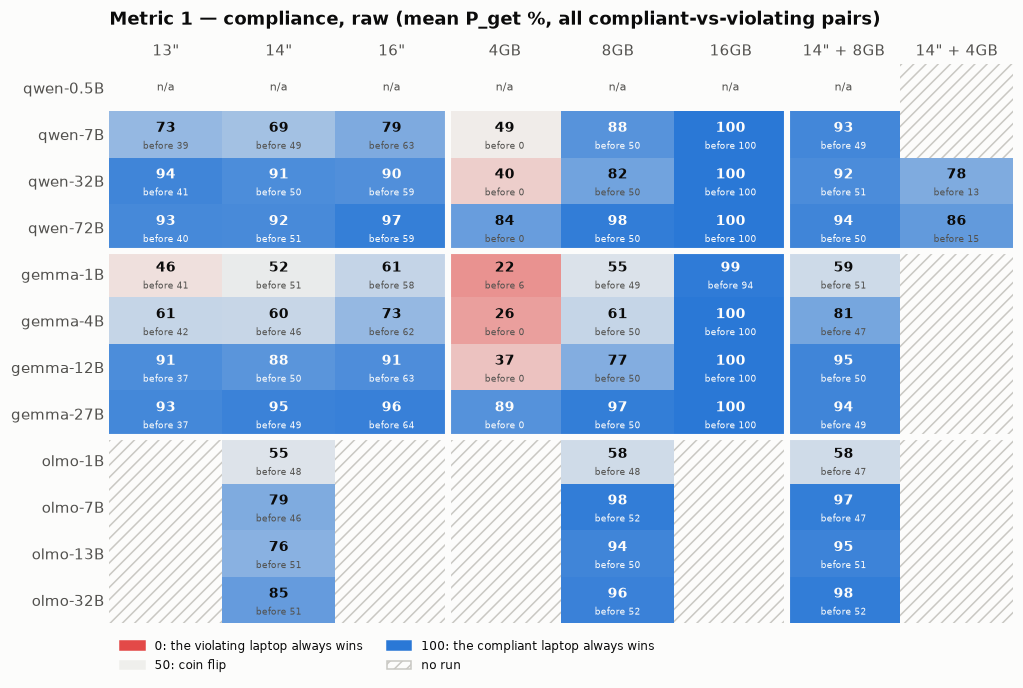

In [6]:
heatmap(COMP, "contract", CON_COLS, "raw", "pct", "Metric 1 — compliance, raw (mean P_get %, all compliant-vs-violating pairs)",
        "M1_compliance_raw.png", sub=lambda r: f"before {r['raw before']:.0f}" if np.isfinite(r["raw before"]) else "",
        groups=[3, 6])

## Metric 2 — compliance gain

Metric 1 also counts pairs the model already got right **before** the contract. A model that ignores
contracts but happens to like 16GB scores ~100 under `16GB`. The gain removes that.

**Pairs:** the same as metric 1. **Value:**

`gain = (raw − raw_before) / (100 − raw_before)`

`raw_before` = metric 1's mean on the same pairs in the default run (the small "before" number).
The denominator is the room there was to improve; the numerator is how much of it the contract used.
1 = everything the model got wrong before is now right, 0 = no change, < 0 = worse. When the default
already wins (almost) every pair — less than 1 point of room — the gain is n/a.

**Example — the same three pairs, before → after:**

| x | y | before | after |
|---|---|---|---|
| Dell 14" 8GB | Dell 14" 4GB | 1.00 | 1.00 — nothing to fix |
| Dell 14" 8GB | Dell 14" 16GB | 0.00 | 0.49 — half fixed |
| Dell 14" 8GB | Apple 16" 16GB | 0.00 | 0.98 — fixed |

All 450 pairs: 50.0% → 81.9%, so **gain = (81.9 − 50.0) / (100 − 50.0) = 0.64**: the contract fixed
64% of what the default got wrong.

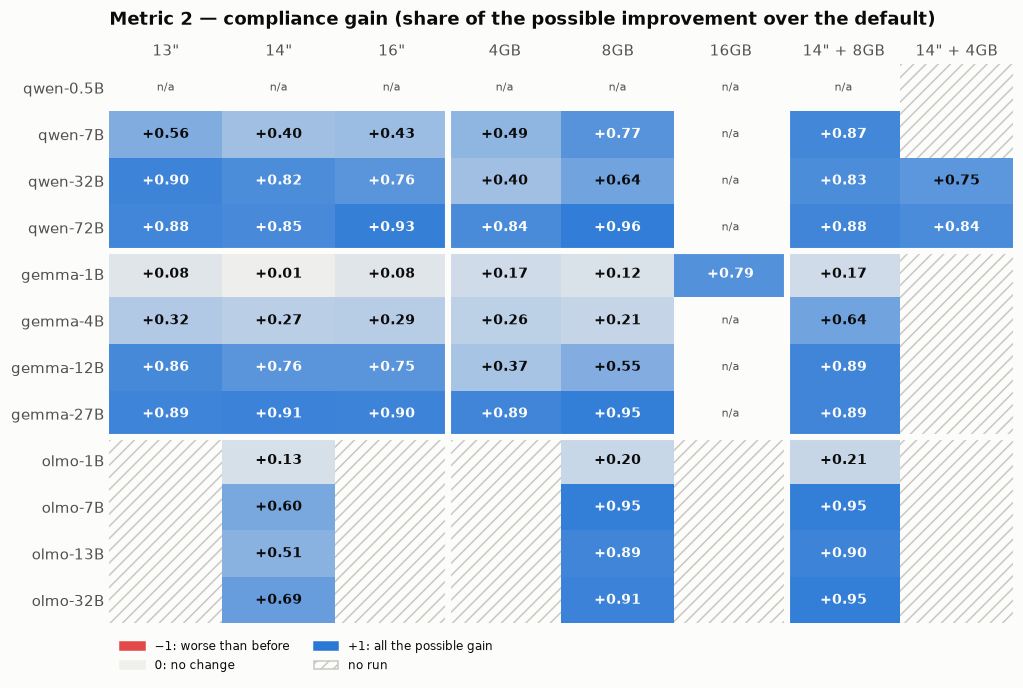

In [7]:
heatmap(COMP, "contract", CON_COLS, "gain", "gain", "Metric 2 — compliance gain (share of the possible improvement over the default)",
        "M2_compliance_gain.png", groups=[3, 6])

## Metric 3 — consistency, INNER (per step)

**Columns are steps**, not contracts: a contract A → the same contract plus one new requirement r.
The first six start from the default (they are the single contracts); the next four add a second
requirement.

**Laptops:** those that meet **r** — always 15 (one level of one feature). **Value:** Spearman between
their ranks in stage A and in stage B. Did adding r reorder the laptops that satisfy it among
themselves?

**Example — qwen-32B, `14"` → `14" + 8GB`** (r = 8GB, the 15 8GB laptops): Apple 14" 8GB drops from
rank 2 to 5 among them, Apple 13" 8GB from 6 to 8, every other laptop moves by at most one place.
**Spearman = +0.96.**

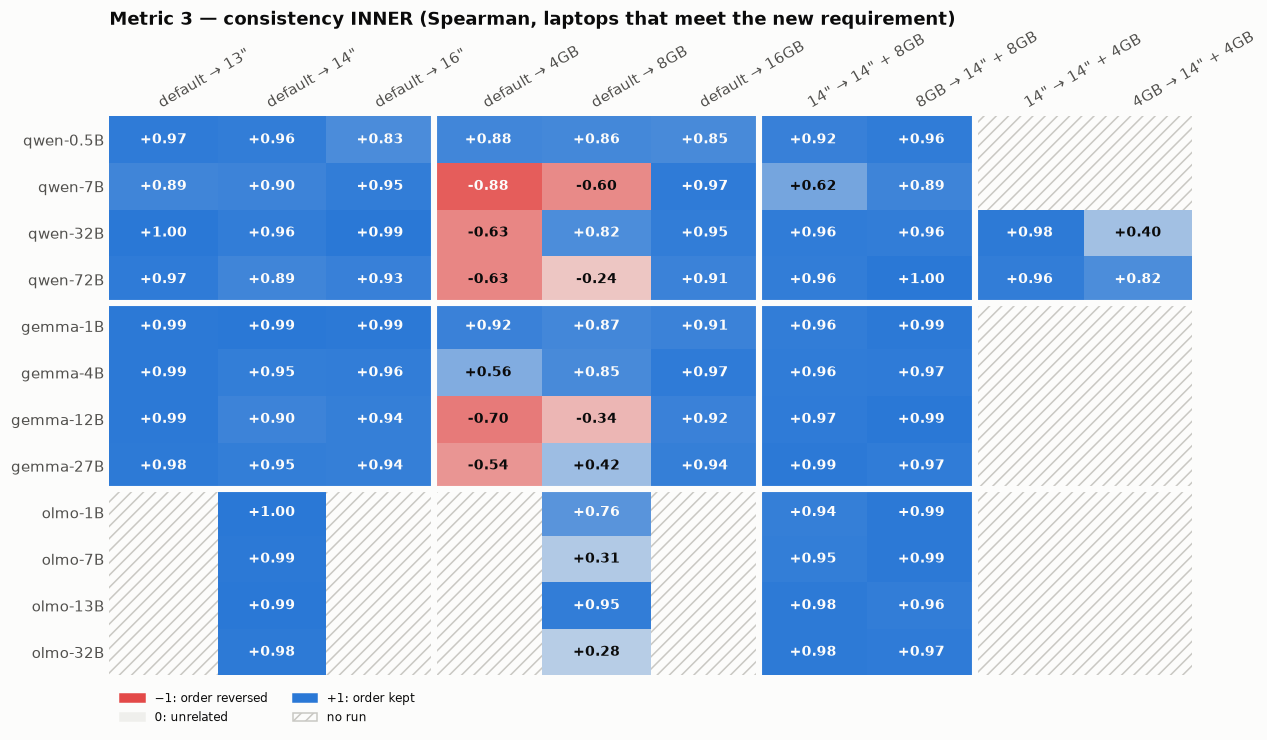

In [8]:
heatmap(CONS, "step", STEP_COLS, "inner", "rho", "Metric 3 — consistency INNER (Spearman, laptops that meet the new requirement)",
        "M3_consistency_inner.png", groups=[3, 6, 8])

## Metric 4 — consistency, OUTER (per step)

**Laptops:** those that do **not** meet the new requirement r — always 30. **Value:** the same Spearman.
Did adding r reorder the laptops it rejects? Under `default → 8GB`, OUTER = the 4GB and 16GB laptops:
a value of 1 means their order is untouched and only the 8GB laptops moved.

**Example — the same step, the 30 non-8GB laptops:** Apple 14" 16GB drops from rank 1 to 5, Apple
13" 16GB from 6 to 10, the rest move by one to three places. **Spearman = +0.98.**

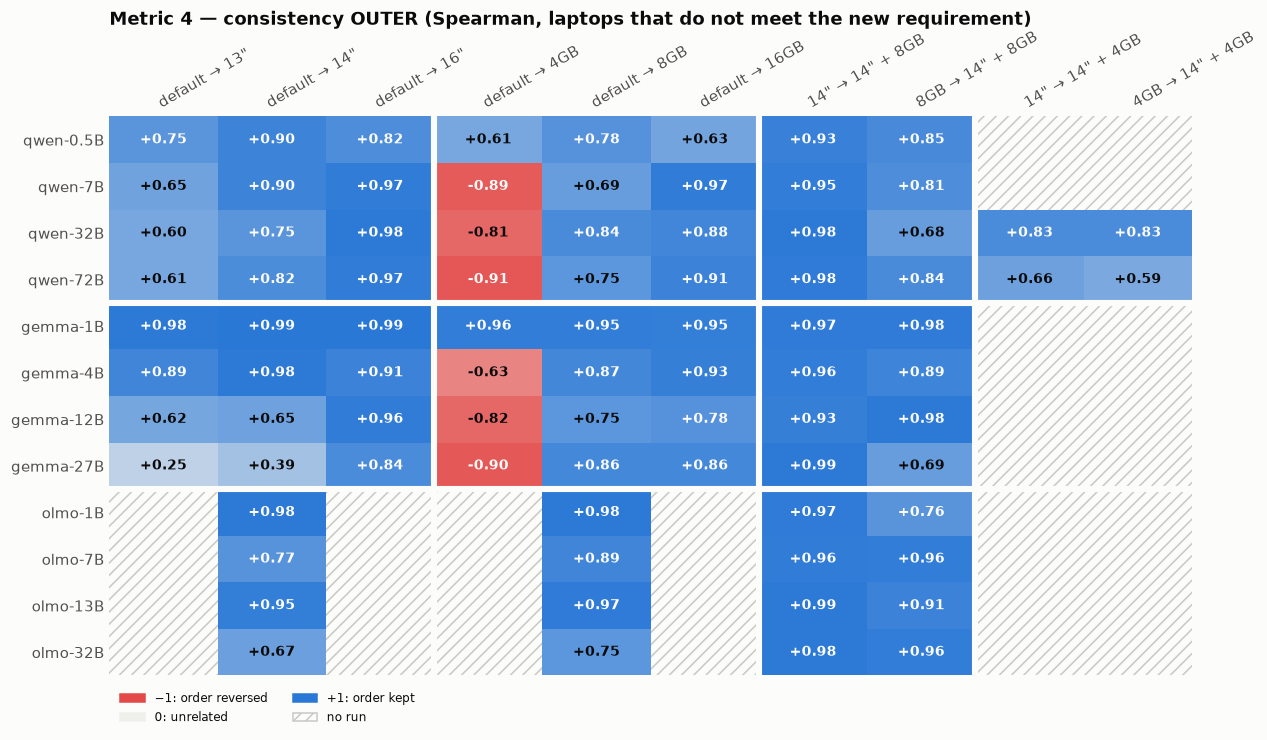

In [9]:
heatmap(CONS, "step", STEP_COLS, "outer", "rho", "Metric 4 — consistency OUTER (Spearman, laptops that do not meet the new requirement)",
        "M4_consistency_outer.png", groups=[3, 6, 8])

## Is there monotonicity in model size?

The same four metrics as lines: **x = model size** (log scale, one panel per family — the sizes differ
by family), **y = the metric**, **one line per contract** (per step for consistency).

Colour = the feature asked (screen pink, RAM blue, both grey), **darker = higher level**
(13" → 16", 4GB → 16GB). For consistency, a **dashed** line is a second step (one requirement added on
top of another); its colour is the *new* requirement, ◆ = the path to `14" + 8GB`, ■ = to `14" + 4GB`.
A gap in a line = no run or undefined (qwen-0.5B has no compliance: its PMI constant is unknown).

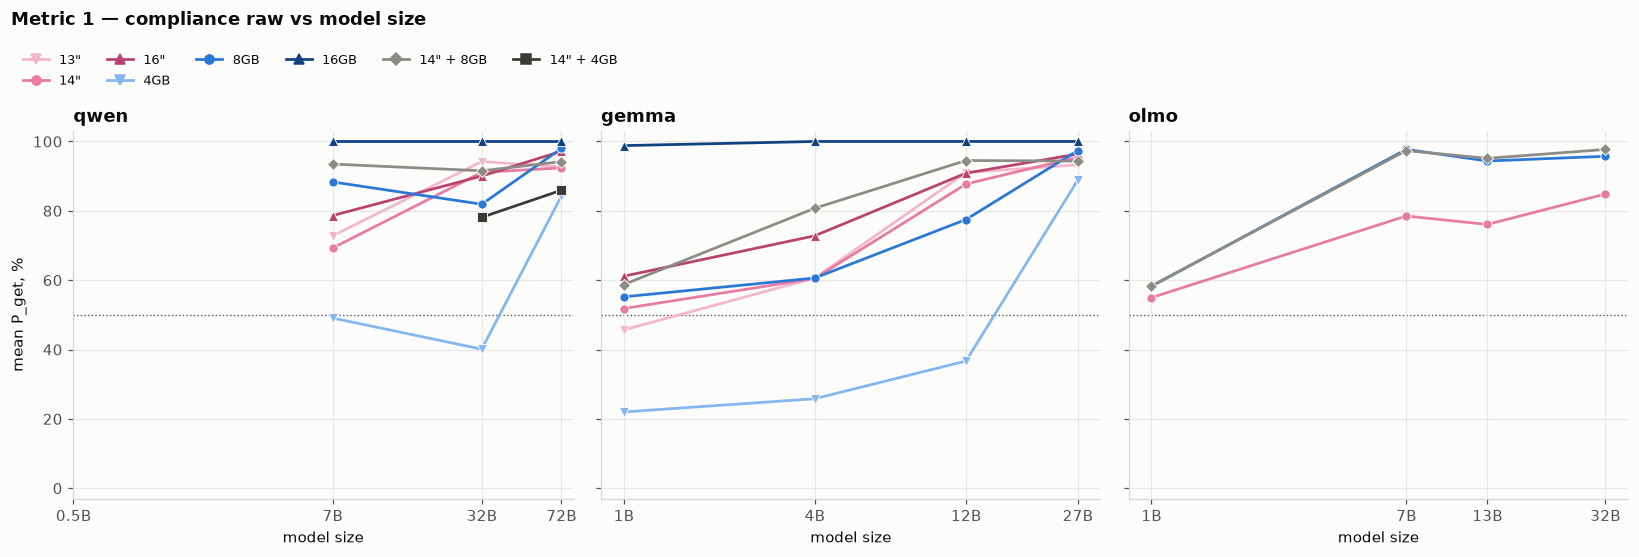

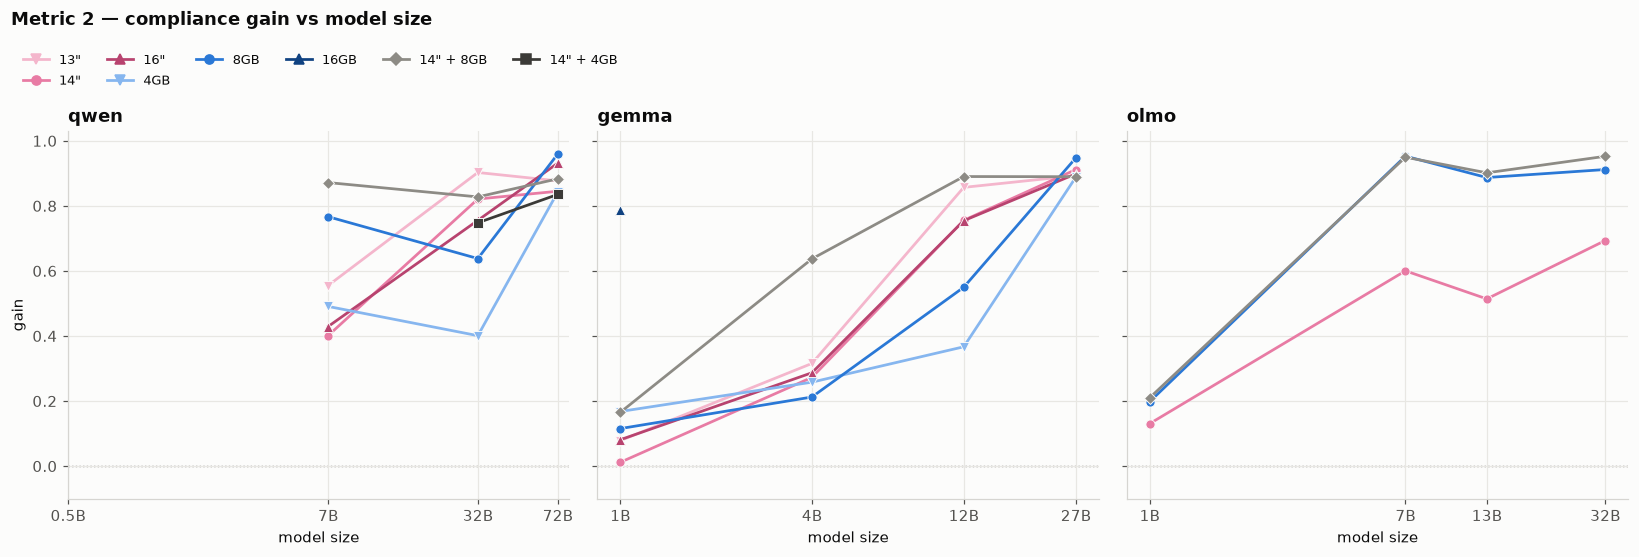

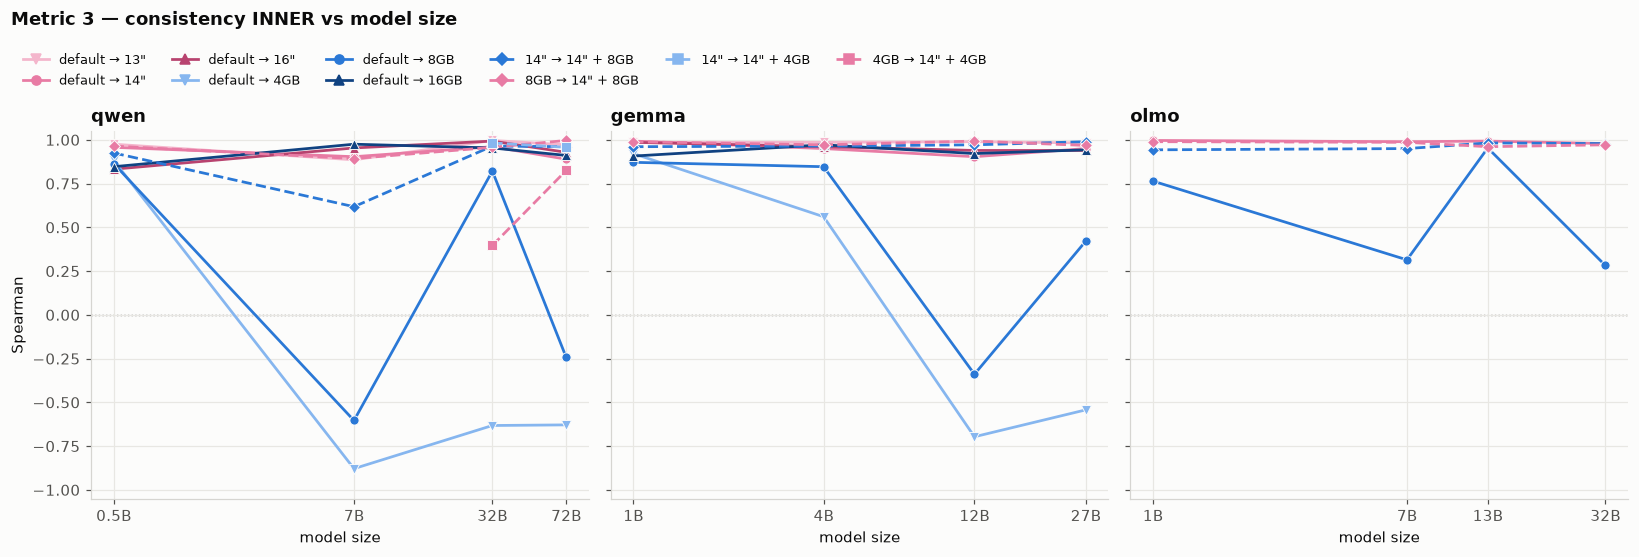

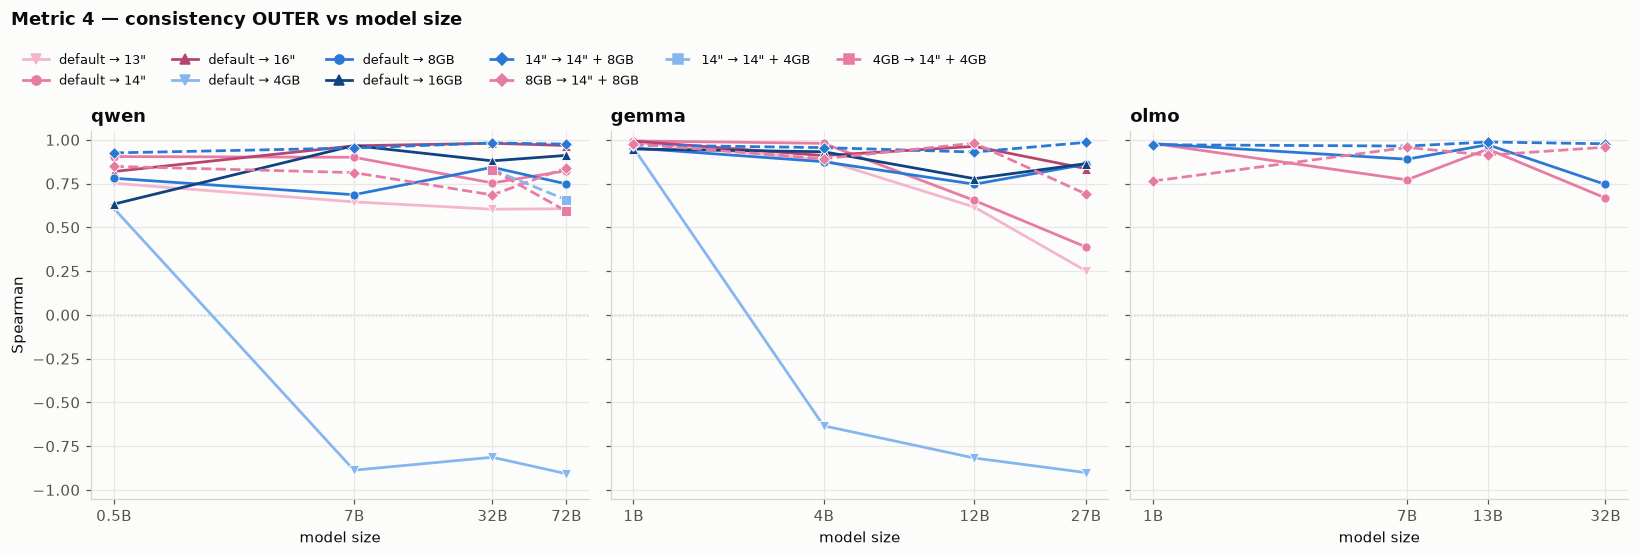

In [10]:
FAM_SIZES = {"qwen": [0.5, 7, 32, 72], "gemma": [1, 4, 12, 27], "olmo": [1, 7, 13, 32]}
SHADE = {'13"': "#f4b6cc", '14"': "#e87ba4", '16"': "#b8436f",
         "4GB": "#86b6ef", "8GB": "#2a78d6", "16GB": "#104281",
         '14" + 8GB': "#8d8b85", '14" + 4GB': "#3b3a37"}
MARK = {'13"': "v", '14"': "o", '16"': "^", "4GB": "v", "8GB": "o", "16GB": "^", '14" + 8GB': "D", '14" + 4GB': "s"}


def split_model(m):
    fam, size = m.split("-")
    return fam, float(size[:-1])


def step_style(step):
    """Colour = the new requirement; dashed = a second step; marker = which double contract it leads to."""
    a, b = step.split(" → ")
    new = b if a == "default" else (b.replace(a, "").strip(" +") or b)
    if a == "default":
        return SHADE.get(new, INK_MUTED), "-", MARK.get(new, "o")
    return SHADE.get(new, INK_MUTED), "--", "D" if "8GB" in b else "s"


def lines(df, key, cols, val, ylim, ref, ylabel, title, fname, style):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
    for ax, (fam, sizes) in zip(axes, FAM_SIZES.items()):
        ax.grid(True, color="#e8e7e3")
        ax.axhline(ref, color=INK_MUTED, lw=0.9, ls=":", zorder=1)
        sub = df[df.model.str.startswith(fam + "-")].copy()
        sub["size"] = sub.model.map(lambda m: split_model(m)[1])
        for col in cols:
            s = sub[sub[key] == col].set_index("size")[val].reindex(sizes)
            if s.notna().sum() == 0:
                continue
            color, ls, mk = style(col)
            ax.plot(sizes, s.values, ls=ls, marker=mk, color=color, lw=1.8, ms=6, label=col,
                    markeredgecolor=SURFACE, markeredgewidth=0.6, zorder=3)
        ax.set_xscale("log")
        ax.set_xticks(sizes, [f"{s:g}B" for s in sizes])
        ax.minorticks_off()
        ax.set_xlabel("model size")
        ax.set_title(fam, loc="left", fontweight="bold")
        ax.set_ylim(*ylim)
    axes[0].set_ylabel(ylabel)
    hs = [plt.Line2D([], [], color=style(c)[0], ls=style(c)[1], marker=style(c)[2], lw=1.8, ms=6, label=c) for c in cols]
    fig.legend(handles=hs, loc="upper left", ncol=min(len(cols), 6), frameon=False, fontsize=8.5, bbox_to_anchor=(0.01, 1.03))
    fig.suptitle(title, x=0.01, y=1.09, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()


con_style = lambda c: (SHADE.get(c, INK_MUTED), "-", MARK.get(c, "o"))
lines(COMP, "contract", CON_COLS, "raw", (-3, 103), 50, "mean P_get, %", "Metric 1 — compliance raw vs model size",
      "L1_compliance_raw_by_size.png", con_style)
lines(COMP, "contract", CON_COLS, "gain", (-0.1, 1.03), 0, "gain", "Metric 2 — compliance gain vs model size",
      "L2_compliance_gain_by_size.png", con_style)
lines(CONS, "step", STEP_COLS, "inner", (-1.05, 1.05), 0, "Spearman", "Metric 3 — consistency INNER vs model size",
      "L3_consistency_inner_by_size.png", step_style)
lines(CONS, "step", STEP_COLS, "outer", (-1.05, 1.05), 0, "Spearman", "Metric 4 — consistency OUTER vs model size",
      "L4_consistency_outer_by_size.png", step_style)